In [103]:
# 회귀분석

# 그래프관련 import
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
# matplotlib.rcParams['font.family'] = 'AppleGothic'
matplotlib.rcParams['axes.unicode_minus']=False
# 프로그램 관련 import
import pandas as pd
from sklearn import svm,metrics
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor # 예측관련(regression)
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error # 평균절대오차 오차범위
from sklearn.neighbors import KNeighborsClassifier # 분류 관련(classifier)
from sklearn.preprocessing import StandardScaler # 정규화클래스
import numpy as np

In [104]:
# 공부시간에 따른 시험점수를 학습해서 시간을 입력하면, 점수를 예측하시오.
# scatter 그래프에 점수와 직선을 표시하시오.

In [105]:
df = pd.read_csv('data/score.csv', sep='\t')
data = df.iloc[:,:-1].values # 0으로 하면, 자료가 1차원으로 되어서 reshape를 해야 함

label = df.iloc[:,1:].values

In [106]:
len(data)
len(label)
data

array([[ 0.5],
       [ 1.2],
       [ 1.8],
       [ 2.4],
       [ 2.6],
       [ 3.2],
       [ 3.9],
       [ 4.4],
       [ 4.5],
       [ 5. ],
       [ 5.3],
       [ 5.8],
       [ 6. ],
       [ 6.1],
       [ 6.2],
       [ 6.9],
       [ 7.2],
       [ 8.4],
       [ 8.6],
       [10. ]])

In [107]:
train_data, test_data, train_label, test_label = \
train_test_split(data,label)

In [108]:
# # 위에서 data = df.iloc[:,0].values 으로 할 경우, 아래와 같이 처리해줘야 함(2차원으로)

# train_data = train_data.reshape(-1,1)
# test_data = test_data.reshape(-1,1)

In [109]:
lr = LinearRegression()
lr.fit(train_data,train_label)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 1)",[[10.83]]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[-1.74]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[9.57]


In [110]:
predict4 = lr.predict(test_data)
score = lr.score(train_data, train_label)
score2 = lr.score(test_data, test_label)
print("정확도", score)
print("정확도", score2)

정확도 0.9637036458494307
정확도 0.9060833675748912


In [113]:
s_h = input("공부시간을 입력하세요:") # 시간을 입력할 경우!!
s_h = float(s_h)
score_pre = lr.predict([[s_h]])
print("예상성적",score_pre)

예상성적 [[74.06441896]]


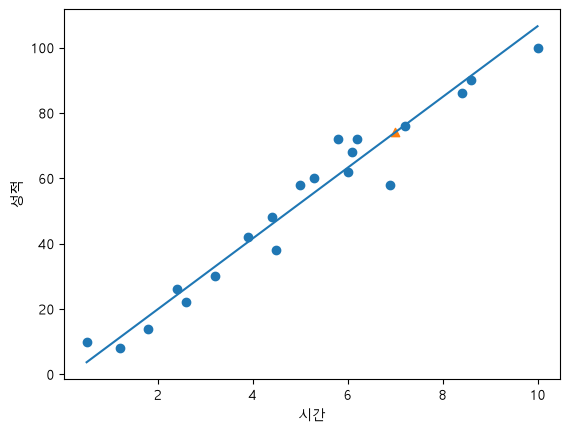

In [ ]:
plt.scatter(data,label)
plt.scatter(7,74.06441896,marker='^')
plt.xlabel('시간')
plt.ylabel('성적')
plt.plot([0.5,10],[0.5*lr.coef_[0] + lr.intercept_, 10*lr.coef_[0]+ lr.intercept_]) # 배열이 두개여서 하나 안으로 들어가야 함
plt.show()